# PAE - 2026-2 Contas RJ

* Instalar e importar bibliotecas

In [1]:
!pip install sqlalchemy psycopg2-binary pandas pyarrow
!pip -q install kneed

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 24.4 MB/s  0:00:00


In [9]:
from sqlalchemy import create_engine, text
from getpass import getpass
from google.colab import files
from sqlalchemy.engine import URL
from pathlib import Path

import os
import sys
import time
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy import sparse
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from kneed import KneeLocator

from scipy.sparse import issparse, csr_matrix

## Conectar Supabase

In [3]:
# insere dados do banco
host = input('Host do Session pooler: ').strip()
usuario = input('Usuário do banco: ').strip()
senha = getpass('Senha do banco: ')

# Monta URL
url = URL.create(
    drivername='postgresql+psycopg2',
    username=usuario,
    password=senha,
    host=host,
    port=5432,
    database='postgres'
)

# Cria Engine
engine = create_engine(
    url,
    connect_args={
        'sslmode': 'require',
        'connect_timeout': 15
    },
    pool_pre_ping=True,
    pool_size=1,
    max_overflow=0
)

# Testa a conexão
try:
    with engine.connect() as conn:
        resultado = conn.execute(
            text('SELECT current_database(), current_schema()')
        ).fetchone()

    print('Conexão realizada com sucesso!')
    print(f'Banco: {resultado[0]}')
    print(f'Schema: {resultado[1]}')
except Exception as e:
    print(f'Erro na conexão: {e}')

Host do Session pooler: aws-0-us-east-1.pooler.supabase.com
Usuário do banco: postgres.aivrloittxzbmbfssdyw
Senha do banco: ··········
Conexão realizada com sucesso!
Banco: postgres
Schema: public


## Consultar dados

In [4]:
# Identifica o schema atual
with engine.connect() as conn:
    schema = conn.execute(
        text("SELECT current_schema()")
    ).scalar_one()

    print(f"Banco de dados: {conn.execute(text('SELECT current_database()')).scalar_one()}")
    print(f"Schema consultado: {schema}")

    # Lista as tabelas existentes
    df_tabelas = pd.read_sql_query(
        text("""
            SELECT table_name
            FROM information_schema.tables
            WHERE table_schema = :schema
              AND table_type = 'BASE TABLE'
            ORDER BY table_name
        """),
        conn,
        params={"schema": schema}
    )

    # Consulta a quantidade de registros de cada tabela
    tabelas_info = []

    preparador = engine.dialect.identifier_preparer
    schema_sql = preparador.quote(schema)

    for tabela in df_tabelas["table_name"]:
        tabela_sql = preparador.quote(tabela)

        quantidade = conn.execute(
            text(f"SELECT COUNT(*) FROM {schema_sql}.{tabela_sql}")
        ).scalar_one()

        tabelas_info.append({
            "Tabela": tabela,
            "Quantidade_registros": quantidade
        })

    df_resumo_tabelas = pd.DataFrame(tabelas_info)

    # Consulta as colunas e seus tipos no PostgreSQL
    df_colunas_sql = pd.read_sql_query(
        text("""
            SELECT
                table_name AS tabela,
                ordinal_position AS ordem,
                column_name AS coluna,
                data_type AS tipo_dado,
                udt_name AS tipo_postgresql,
                is_nullable AS aceita_nulo
            FROM information_schema.columns
            WHERE table_schema = :schema
            ORDER BY table_name, ordinal_position
        """),
        conn,
        params={"schema": schema}
    )

# Apresenta os resultados
print("\n=== TABELAS E QUANTIDADE DE REGISTROS ===")
display(df_resumo_tabelas)

print("\n=== COLUNAS E TIPOS DE DADOS ===")
display(df_colunas_sql)

print(f"\nTotal de tabelas encontradas: {len(df_resumo_tabelas)}")
print(f"Total de colunas encontradas: {len(df_colunas_sql)}")

Banco de dados: postgres
Schema consultado: public

=== TABELAS E QUANTIDADE DE REGISTROS ===


,Tabela,Quantidade_registros
0,dim_afastamento,1748
1,dim_fornecedor,3755
2,dim_processo,11452
3,dim_unidade,97
4,fato_item_compra,19676



=== COLUNAS E TIPOS DE DADOS ===


,tabela,ordem,coluna,tipo_dado,tipo_postgresql,aceita_nulo
0,dim_afastamento,1,id_afastamento,integer,int4,NO
1,dim_afastamento,2,tipo_afastamento,character varying,varchar,NO
2,dim_afastamento,3,enquadramento_legal,text,text,NO
3,dim_fornecedor,1,id_fornecedor,integer,int4,NO
4,dim_fornecedor,2,nome_fornecedor,character varying,varchar,NO
5,dim_processo,1,id_processo,integer,int4,NO
6,dim_processo,2,numero_processo,character varying,varchar,NO
7,dim_processo,3,ano_processo,integer,int4,NO
8,dim_processo,4,data_aprovacao,date,date,NO
9,dim_processo,5,objeto,text,text,NO



Total de tabelas encontradas: 5
Total de colunas encontradas: 45


## Montar base analítica

In [5]:
# ============================================================
# EXTRAÇÃO DOS DADOS DO SUPABASE PARA MACHINE LEARNING
# ============================================================

consulta_base_ml = """
SELECT
    -- Identificação do registro e do processo
    f.id_item_compra,
    f.id_processo,
    p.numero_processo,
    p.ano_processo,
    p.data_aprovacao,

    -- Informações do processo
    p.valor_total_processo,
    p.objeto,

    -- Unidade contratante
    f.id_unidade,
    u.nome_unidade AS unidade,

    -- Fornecedor
    f.id_fornecedor,
    fo.nome_fornecedor AS fornecedor,

    -- Afastamento e enquadramento legal
    f.id_afastamento,
    a.tipo_afastamento AS afastamento,
    a.enquadramento_legal,

    -- Informações dos itens
    f.descricao_item AS item,
    f.unidade_medida,
    f.quantidade,
    f.valor_unitario,
    f.valor_calculado_item

FROM public.fato_item_compra AS f

INNER JOIN public.dim_processo AS p
    ON p.id_processo = f.id_processo

LEFT JOIN public.dim_unidade AS u
    ON u.id_unidade = f.id_unidade

LEFT JOIN public.dim_fornecedor AS fo
    ON fo.id_fornecedor = f.id_fornecedor

LEFT JOIN public.dim_afastamento AS a
    ON a.id_afastamento = f.id_afastamento

ORDER BY
    p.ano_processo,
    p.id_processo,
    f.id_item_compra
"""

# Executar consulta no Supabase
with engine.connect() as conn:
    df_ml_base = pd.read_sql_query(
        text(consulta_base_ml),
        conn
    )

# ------------------------------------------------------------
# AJUSTE DOS TIPOS DE DADOS
# ------------------------------------------------------------

# Variáveis numéricas
colunas_numericas = [
    'valor_total_processo',
    'quantidade',
    'valor_unitario',
    'valor_calculado_item'
]

for coluna in colunas_numericas:
    df_ml_base[coluna] = pd.to_numeric(
        df_ml_base[coluna],
        errors='coerce'
    )

# Data de aprovação
df_ml_base['data_aprovacao'] = pd.to_datetime(
    df_ml_base['data_aprovacao'],
    errors='coerce'
)

# Ano do processo
df_ml_base['ano_processo'] = pd.to_numeric(
    df_ml_base['ano_processo'],
    errors='coerce'
).astype('Int64')

# ------------------------------------------------------------
# VERIFICAÇÃO DA BASE EXTRAÍDA
# ------------------------------------------------------------

print("=" * 55)
print("RESUMO DA BASE PARA MACHINE LEARNING")
print("=" * 55)

print(f"\nRegistros de itens: {len(df_ml_base):,}")

print(
    f"Processos distintos: "
    f"{df_ml_base['id_processo'].nunique():,}"
)

print(
    f"Itens de compra distintos: "
    f"{df_ml_base['id_item_compra'].nunique():,}"
)

print(
    f"Fornecedores distintos: "
    f"{df_ml_base['id_fornecedor'].nunique():,}"
)

print(
    f"Unidades distintas: "
    f"{df_ml_base['id_unidade'].nunique():,}"
)

print(
    f"Tipos de afastamento distintos: "
    f"{df_ml_base['afastamento'].nunique():,}"
)

print("\nValores ausentes:")
display(
    df_ml_base.isna().sum().to_frame('valores_ausentes')
)

print("\nTipos de dados:")
display(
    df_ml_base.dtypes.to_frame('tipo_dado')
)

print("\nAmostra da base:")
display(df_ml_base.head())

# Verificação de duplicidade da chave dos itens
print(
    "\nItens com identificador duplicado:",
    df_ml_base['id_item_compra'].duplicated().sum()
)


RESUMO DA BASE PARA MACHINE LEARNING

Registros de itens: 19,676
Processos distintos: 11,452
Itens de compra distintos: 19,676
Fornecedores distintos: 3,755
Unidades distintas: 97
Tipos de afastamento distintos: 7

Valores ausentes:


,valores_ausentes
id_item_compra,0
id_processo,0
numero_processo,0
ano_processo,0
data_aprovacao,0
valor_total_processo,0
objeto,0
id_unidade,0
unidade,0
id_fornecedor,0



Tipos de dados:


,tipo_dado
id_item_compra,int64
id_processo,int64
numero_processo,object
ano_processo,Int64
data_aprovacao,datetime64[ns]
valor_total_processo,float64
objeto,object
id_unidade,int64
unidade,object
id_fornecedor,int64



Amostra da base:


,id_item_compra,id_processo,numero_processo,ano_processo,data_aprovacao,valor_total_processo,objeto,id_unidade,unidade,id_fornecedor,fornecedor,id_afastamento,afastamento,enquadramento_legal,item,unidade_medida,quantidade,valor_unitario,valor_calculado_item
0,1,1,**SEI-120001/009348/2022,2023,2023-07-05,10994.00,CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,82,SEPLAG - Secretaria de Estado de Planejamento ...,2353,MAR E FIRE EQUIP. E PROT. CONTRA INCÊNDIO LTDA-ME,1,Dispensa - Pequenas Compras,"De acordo com o artigo24, inciso 2º da Lei Fed...",MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,SERVICO,1.0,10994.00,10994.00
1,65,61,020002/000814/2023,2023,2023-07-13,7199.28,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,17,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,2207,LESTE GROUP TELECOMUNICACOES DO BRASIL LTDA,14,Dispensa - Pequenas Compras,Lei 13303/16 art.29 Inciso II,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,SERVICO,12.0,599.94,7199.28
2,66,62,020002/000819/2023,2023,2023-07-13,3599.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,17,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,1601,GIGALINK DE NOVA FRIBURGO SOLUCOES EM REDE MUL...,15,Dispensa - Pequenas Compras,"Dispensa Licitação no artigo 29, Inciso II da ...",SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,SERVICO,12.0,299.98,3599.76
3,67,63,020002/000821/2023,2023,2023-07-13,4079.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,17,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3468,TELEFONICA BRASIL S/A.,16,Dispensa - Pequenas Compras,Lei 13303/16 Art.29 Inciso II,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,SERVICO,12.0,339.98,4079.76
4,71,66,020002/000917/2023,2023,2023-08-21,234999.96,1 FORNECIMENTO DE ENERGIA ELETRICADESCRIÇÃO CO...,17,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,278,AMPLA ENERGIA E SERVIÇOS S/A,17,Dispensa - Especial,"Art. 29, Inciso X da Lei Federal nº 13.303/16",FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,SERVICO,6.0,39166.66,234999.96



Itens com identificador duplicado: 0


## Preparar Variáveis.

In [6]:
def preparar_features(df):

    df_prep = df.copy()

    # --------------------------------------------------------
    # 1. TRATAMENTO DAS VARIÁVEIS NUMÉRICAS
    # --------------------------------------------------------

    colunas_numericas = [
        'valor_unitario',
        'valor_total_processo',
        'quantidade',
        'valor_calculado_item'
    ]

    for col in colunas_numericas:
        df_prep[col] = pd.to_numeric(
            df_prep[col],
            errors='coerce'
        ).fillna(0)

    # --------------------------------------------------------
    # 2. TRANSFORMAÇÕES LOGARÍTMICAS
    # --------------------------------------------------------

    df_prep['log_valor_unitario'] = np.log1p(
        np.maximum(0, df_prep['valor_unitario'])
    )

    df_prep['log_valor_processo'] = np.log1p(
        np.maximum(0, df_prep['valor_total_processo'])
    )

    df_prep['log_quantidade'] = np.log1p(
        np.maximum(0, df_prep['quantidade'])
    )

    # --------------------------------------------------------
    # 3. PROPORÇÃO DO VALOR DO ITEM NO PROCESSO
    # --------------------------------------------------------

    df_prep['proporcao_item_processo'] = np.where(
        df_prep['valor_total_processo'] > 0,
        df_prep['valor_calculado_item'] /
        df_prep['valor_total_processo'],
        0
    )

    # --------------------------------------------------------
    # 4. SELEÇÃO DAS FEATURES
    # --------------------------------------------------------

    features_numericas = [
        'log_valor_unitario',
        'log_valor_processo',
        'log_quantidade',
        'proporcao_item_processo'
    ]

    # Garantir ausência de valores infinitos ou nulos
    df_prep[features_numericas] = (
        df_prep[features_numericas]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    # --------------------------------------------------------
    # 5. NORMALIZAÇÃO COM ROBUST SCALER
    # --------------------------------------------------------

    scaler = RobustScaler()

    X_scaled = scaler.fit_transform(
        df_prep[features_numericas]
    )

    return df_prep, X_scaled, features_numericas, scaler


# ============================================================
# EXECUÇÃO
# ============================================================

df_ml_prep, X_scaled, features_numericas, scaler = (
    preparar_features(df_ml_base)
)

# Matriz sem escalonamento para Isolation Forest
X_iforest = df_ml_prep[features_numericas].copy()

# ============================================================
# VERIFICAÇÃO DOS RESULTADOS
# ============================================================

print("=" * 55)
print("PREPARAÇÃO DAS FEATURES")
print("=" * 55)

print(f"\nRegistros preparados: {len(df_ml_prep):,}")
print(f"Quantidade de features: {len(features_numericas)}")

print("\nFeatures selecionadas:")
for feature in features_numericas:
    print(f"- {feature}")

print("\nDimensão da matriz K-Means:", X_scaled.shape)
print("Dimensão da matriz Isolation Forest:", X_iforest.shape)

print("\nEstatísticas das features:")
display(
    df_ml_prep[features_numericas].describe().T
)

print("\nAmostra das variáveis preparadas:")
display(
    df_ml_prep[
        ['id_processo', 'item'] + features_numericas
    ].head()
)

# Verificação de valores inválidos
print("\nValores ausentes nas features:")
display(
    df_ml_prep[features_numericas].isna().sum()
)

print("\nValores infinitos nas features:")
print(
    np.isinf(
        df_ml_prep[features_numericas].to_numpy()
    ).sum()
)


PREPARAÇÃO DAS FEATURES

Registros preparados: 19,676
Quantidade de features: 4

Features selecionadas:
- log_valor_unitario
- log_valor_processo
- log_quantidade
- proporcao_item_processo

Dimensão da matriz K-Means: (19676, 4)
Dimensão da matriz Isolation Forest: (19676, 4)

Estatísticas das features:


,count,mean,std,min,25%,50%,75%,max
log_valor_unitario,19676.0,7.512872,4.244801,0.000000,3.663562,7.777587,10.813223,20.307750
log_valor_processo,19676.0,11.105334,2.449296,0.009950,9.426661,10.705106,12.632270,20.307750
log_quantidade,19676.0,2.388602,2.521681,0.506818,0.693147,1.098612,3.433987,16.336870
proporcao_item_processo,19676.0,0.557962,0.455008,0.000000,0.044978,0.800023,1.000000,1.018182



Amostra das variáveis preparadas:


,id_processo,item,log_valor_unitario,log_valor_processo,log_quantidade,proporcao_item_processo
0,1,MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,9.305196,9.305196,0.693147,1.0
1,61,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,6.398495,8.881875,2.564949,1.0
2,62,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,5.707044,8.188900,2.564949,1.0
3,63,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,5.831824,8.314039,2.564949,1.0
4,66,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,10.575607,12.367345,1.945910,1.0



Valores ausentes nas features:


,0
log_valor_unitario,0
log_valor_processo,0
log_quantidade,0
proporcao_item_processo,0



Valores infinitos nas features:
0


## Isolation Forest

In [8]:
# ------------------------------------------------------------
# 1. CONFIGURAÇÃO DO MODELO
# ------------------------------------------------------------

modelo_if = IsolationForest(
    n_estimators=300,
    max_samples='auto',
    contamination=0.05,
    max_features=1.0,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 2. TREINAMENTO E PREDIÇÃO
# ------------------------------------------------------------

modelo_if.fit(X_iforest)

# Predição:
#  1 = Normal
# -1 = Anomalia

predicoes = modelo_if.predict(X_iforest)

# Score de anomalia:
# Quanto maior, mais atípico o registro.
scores = -modelo_if.score_samples(X_iforest)

# ------------------------------------------------------------
# 3. INCORPORAR RESULTADOS AO DATAFRAME
# ------------------------------------------------------------

df_ml_prep['resultado_isolation_forest'] = predicoes

df_ml_prep['anomalia_isolation_forest'] = (
    df_ml_prep['resultado_isolation_forest'] == -1
).astype(int)

df_ml_prep['score_isolation_forest'] = scores

# ------------------------------------------------------------
# 4. RESUMO DOS RESULTADOS
# ------------------------------------------------------------

total = len(df_ml_prep)

normais = (predicoes == 1).sum()
anomalias = (predicoes == -1).sum()

print("=" * 60)
print("RESULTADO DO ISOLATION FOREST")
print("=" * 60)

print(f"\nTotal de registros: {total:,}")
print(f"Registros normais: {normais:,}")
print(f"Registros anômalos: {anomalias:,}")

print(
    f"Percentual de anomalias: "
    f"{anomalias / total * 100:.2f}%"
)

# ------------------------------------------------------------
# 5. ESTATÍSTICAS DOS SCORES
# ------------------------------------------------------------

print("\nEstatísticas dos scores de anomalia:")

display(
    df_ml_prep['score_isolation_forest']
    .describe()
    .to_frame('score')
)

# ------------------------------------------------------------
# 6. DISTRIBUIÇÃO DAS CLASSIFICAÇÕES
# ------------------------------------------------------------

print("\nDistribuição das classificações:")

display(
    df_ml_prep['anomalia_isolation_forest']
    .value_counts()
    .rename(index={
        0: 'Normal',
        1: 'Anomalia'
    })
    .to_frame('quantidade')
)

# ------------------------------------------------------------
# 7. AMOSTRA DOS REGISTROS ANÔMALOS
# ------------------------------------------------------------

df_anomalias_if = (
    df_ml_prep[
        df_ml_prep['anomalia_isolation_forest'] == 1
    ]
    .sort_values(
        'score_isolation_forest',
        ascending=False
    )
    .copy()
)

colunas_exibicao = [
    'numero_processo',
    'ano_processo',
    'unidade',
    'fornecedor',
    'afastamento',
    'item',
    'valor_unitario',
    'quantidade',
    'valor_total_processo',
    'proporcao_item_processo',
    'score_isolation_forest'
]

print("\n10 registros mais atípicos:")

display(
    df_anomalias_if[colunas_exibicao].head(10)
)


RESULTADO DO ISOLATION FOREST

Total de registros: 19,676
Registros normais: 18,692
Registros anômalos: 984
Percentual de anomalias: 5.00%

Estatísticas dos scores de anomalia:


,score
count,19676.000000
mean,0.468481
std,0.061352
min,0.388888
25%,0.422717
50%,0.457577
75%,0.503036
max,0.709607



Distribuição das classificações:


,quantidade
anomalia_isolation_forest,
Normal,18692
Anomalia,984



10 registros mais atípicos:


,numero_processo,ano_processo,unidade,fornecedor,afastamento,item,valor_unitario,quantidade,valor_total_processo,proporcao_item_processo,score_isolation_forest
4439,SEI-260007/051021/2023,2023,UERJ - ADMINISTRACAO CENTRAL,CONQUISTA SERVICO E TERCEIRIZACAO DE MAO DE OB...,Dispensa - Especial,LIMPEZA PREDIAL - SERVICO: EMPRESA ESPECIALIZA...,2.14,4575529.80,9.795294e+06,0.999626,0.709607
8407,SEI-080002/000349/2024,2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,LUVA PROCEDIMENTO DESCARTAVEL - TIPO: NAO ESTE...,0.28,12445505.00,4.830946e+06,0.721337,0.706062
11417,SEI-260006/024108/2024,2024,UERJ - ADMINISTRACAO CENTRAL,CONQUISTA SERVICO E TERCEIRIZACAO DE MAO DE OB...,Dispensa de Licitação,SERVICOS DE LIMPEZA E CONSERVACAO DE AMBIENTE ...,2.58,2287764.87,5.908839e+06,0.998916,0.704336
8805,SEI-080002/002636/2024,2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,"FRALDA GERIATRICA DESCARTAVEL - MODELO: CALCA,...",1.19,5433898.00,1.191921e+07,0.542514,0.700742
8873,SEI-080002/003250/2024,2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,"S.M GUIMARÃES DISTRIBUIDORA, IMPORTDORA E EXPO...",Dispensa de Licitação,CONECTOR CATETER - MATERIAL: CLORETO POLIVILIN...,1.89,1611979.00,4.271688e+06,0.713217,0.698575
14002,SEI-030001/103373/A/2024,2025,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,Inexigibilidade - 14.133/2021,LIVRO DIDATICO - TITULO: ENSINO MEDIO EM FOCO ...,582.83,189617.00,3.343364e+08,0.330549,0.697865
1606,SEI-080007/001394/2023,2023,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa - Especial,MEDICAMENTO USO HUMANO - GRUPO FARMACOLOGICO: ...,7.45,597540.00,4.769097e+06,0.933441,0.697290
13510,SEI-420001/002556/2024,2024,SEGOV - Secretaria de Estado de Governo,AGS COMÉRCIO E SERVIÇOS LTDA - EPP,Inexigibilidade - 14.133/2021,BOCAL BAFOMETRO/ETILOMETRO - MODELO COMPATIVEL...,3.00,1300000.00,3.900000e+06,1.000000,0.696148
13511,SEI-420001/002556A/2024,2024,SEGOV - Secretaria de Estado de Governo,AGS COMÉRCIO E SERVIÇOS LTDA - EPP,Inexigibilidade - 14.133/2021,BOCAL BAFOMETRO/ETILOMETRO - MODELO COMPATIVEL...,3.00,1300000.00,3.900000e+06,1.000000,0.696148
8744,SEI-080002/001811/2024,2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,FILME PARA MAMOGRAFIA - MODELO: IMAGEM LASER P...,12.00,510336.00,7.027292e+06,0.871464,0.696026


## K-means

### Teste cotovelo, Silhouette e n_init

Testando n_init = 5
Testando n_init = 10
Testando n_init = 20
Testando n_init = 50


,n_init,k,inercia,silhouette,tempo_segundos
0,5,20,3114.4580,0.3566,3.3820
1,5,21,2961.5223,0.3583,4.6575
2,5,22,2875.8092,0.3570,3.5855
3,5,23,2808.3690,0.3544,5.2919
4,5,24,2685.4272,0.3550,3.9945
...,...,...,...,...,...
75,50,35,1918.2387,0.3624,7.5219
76,50,36,1866.9345,0.3639,7.9381
77,50,37,1824.7635,0.3654,7.1757
78,50,38,1791.9049,0.3682,8.1670


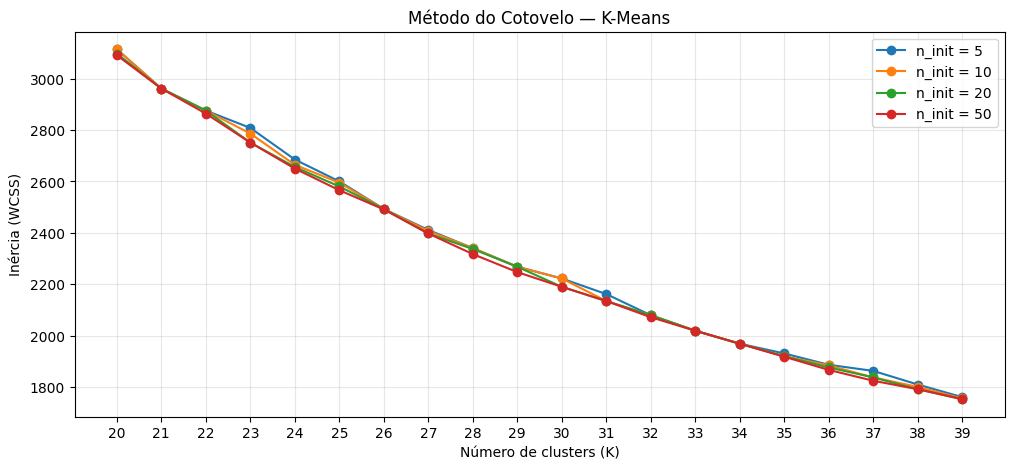

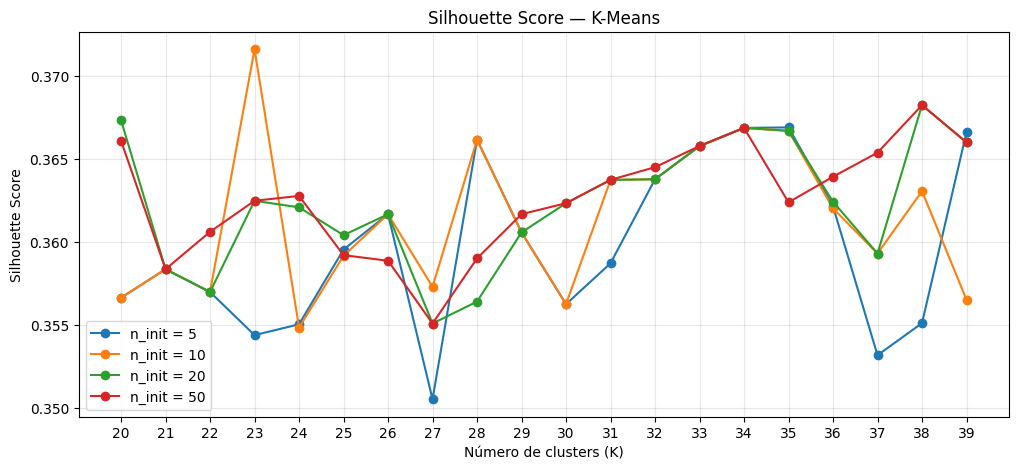

Melhor K por n_init, considerando Silhouette:


,n_init,k,inercia,silhouette,tempo_segundos
15,5,35,1930.8626,0.3669,3.6348
23,10,23,2786.5438,0.3716,3.9871
58,20,38,1791.9049,0.3682,5.0732
78,50,38,1791.9049,0.3682,8.1670


In [10]:
# Configurações dos testes
valores_k = range(20, 40)
valores_n_init = [5, 10, 20, 50]

resultados = []

# Executa os testes
for n_init in valores_n_init:

    print(f"Testando n_init = {n_init}")

    for k in valores_k:

        inicio = time.time()

        modelo = KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=n_init,
            max_iter=300,
            random_state=42
        )

        clusters = modelo.fit_predict(X_scaled)

        # Métricas
        inercia = modelo.inertia_
        silhouette = silhouette_score(
            X_scaled,
            clusters
        )

        tempo = time.time() - inicio

        resultados.append({
            'n_init': n_init,
            'k': k,
            'inercia': inercia,
            'silhouette': silhouette,
            'tempo_segundos': tempo
        })

# Consolida resultados
df_resultados_kmeans = pd.DataFrame(resultados)

# Exibe os resultados
display(
    df_resultados_kmeans.sort_values(
        ['n_init', 'k']
    ).round(4)
)

# Gráfico do cotovelo
plt.figure(figsize=(12, 5))

for n_init in valores_n_init:
    dados = df_resultados_kmeans[
        df_resultados_kmeans['n_init'] == n_init
    ]

    plt.plot(
        dados['k'],
        dados['inercia'],
        marker='o',
        label=f'n_init = {n_init}'
    )

plt.title('Método do Cotovelo — K-Means')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inércia (WCSS)')
plt.xticks(list(valores_k))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Gráfico Silhouette
plt.figure(figsize=(12, 5))

for n_init in valores_n_init:
    dados = df_resultados_kmeans[
        df_resultados_kmeans['n_init'] == n_init
    ]

    plt.plot(
        dados['k'],
        dados['silhouette'],
        marker='o',
        label=f'n_init = {n_init}'
    )

plt.title('Silhouette Score — K-Means')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(valores_k))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Melhor resultado de cada configuração
melhores_resultados = (
    df_resultados_kmeans
    .sort_values('silhouette', ascending=False)
    .groupby('n_init')
    .head(1)
    .sort_values('n_init')
)

print("Melhor K por n_init, considerando Silhouette:")
display(melhores_resultados.round(4))


In [11]:
resultados_k34 = []
rotulos_k34 = {}

for n_init in [5, 10, 20, 50]:

    modelo = KMeans(
        n_clusters=34,
        init='k-means++',
        n_init=n_init,
        max_iter=300,
        random_state=42
    )

    clusters = modelo.fit_predict(X_scaled)

    resultados_k34.append({
        'n_init': n_init,
        'inercia': modelo.inertia_,
        'silhouette': silhouette_score(X_scaled, clusters),
        'iteracoes': modelo.n_iter_
    })

    rotulos_k34[n_init] = clusters

df_comparacao_k34 = pd.DataFrame(resultados_k34)

display(df_comparacao_k34.round(6))

# Verifica se os agrupamentos são idênticos
for n_init in [10, 20, 50]:

    iguais = np.array_equal(
        rotulos_k34[5],
        rotulos_k34[n_init]
    )

    print(f"n_init 5 e {n_init}: agrupamentos idênticos? {iguais}")


,n_init,inercia,silhouette,iteracoes
0,5,1968.854008,0.366858,68
1,10,1968.854008,0.366858,68
2,20,1968.854008,0.366858,68
3,50,1968.854008,0.366858,68


n_init 5 e 10: agrupamentos idênticos? True
n_init 5 e 20: agrupamentos idênticos? True
n_init 5 e 50: agrupamentos idênticos? True


## Gerar clusters com k=34 n_init =5

In [13]:
# Configuração definitiva
modelo_kmeans = KMeans(
    n_clusters=34,
    init='k-means++',
    n_init=5,
    max_iter=300,
    random_state=42
)

# Treinamento e identificação dos clusters
clusters_kmeans = modelo_kmeans.fit_predict(X_scaled)

# Incorpora os resultados ao dataframe preparado
df_ml_prep['cluster_kmeans'] = clusters_kmeans

# Métricas gerais do modelo
inercia_kmeans = modelo_kmeans.inertia_
silhouette_kmeans = silhouette_score(X_scaled, clusters_kmeans)

print("RESULTADOS DO K-MEANS")
print(f"Número de clusters: {modelo_kmeans.n_clusters}")
print(f"n_init: {modelo_kmeans.n_init}")
print(f"Inércia: {inercia_kmeans:.6f}")
print(f"Silhouette Score: {silhouette_kmeans:.6f}")
print(f"Iterações: {modelo_kmeans.n_iter_}")

# Distribuição dos registros por cluster
distribuicao_clusters = (
    df_ml_prep['cluster_kmeans']
    .value_counts()
    .sort_index()
    .rename_axis('cluster')
    .reset_index(name='quantidade_registros')
)

distribuicao_clusters['percentual'] = (
    distribuicao_clusters['quantidade_registros']
    / len(df_ml_prep) * 100
)

print("\nDISTRIBUIÇÃO DOS CLUSTERS")
display(distribuicao_clusters.round(2))

# Estatísticas descritivas por cluster
resumo_clusters = (
    df_ml_prep
    .groupby('cluster_kmeans')
    .agg(
        registros=('cluster_kmeans', 'size'),
        valor_unitario_medio=('valor_unitario', 'mean'),
        valor_unitario_mediano=('valor_unitario', 'median'),
        valor_processo_medio=('valor_total_processo', 'mean'),
        quantidade_media=('quantidade', 'mean'),
        fornecedores_distintos=('fornecedor', 'nunique'),
        unidades_distintas=('unidade', 'nunique')
    )
    .reset_index()
)

print("\nRESUMO DOS CLUSTERS")
display(resumo_clusters.round(2))

# Conferência da quantidade de registros
print("\nCONFERÊNCIA")
print(f"Registros na base: {len(df_ml_prep)}")
print(f"Registros classificados: {distribuicao_clusters['quantidade_registros'].sum()}")
print(f"Clusters encontrados: {df_ml_prep['cluster_kmeans'].nunique()}")


RESULTADOS DO K-MEANS
Número de clusters: 34
n_init: 5
Inércia: 1968.854008
Silhouette Score: 0.366858
Iterações: 68

DISTRIBUIÇÃO DOS CLUSTERS


,cluster,quantidade_registros,percentual
0,0,397,2.02
1,1,592,3.01
2,2,78,0.40
3,3,252,1.28
4,4,1227,6.24
5,5,544,2.76
6,6,265,1.35
7,7,1769,8.99
8,8,618,3.14
9,9,277,1.41



RESUMO DOS CLUSTERS


,cluster_kmeans,registros,valor_unitario_medio,valor_unitario_mediano,valor_processo_medio,quantidade_media,fornecedores_distintos,unidades_distintas
0,0,397,177683.85,62500.00,2.686419e+06,1.77,122,43
1,1,592,1562.69,1037.50,1.065596e+04,1.66,211,64
2,2,78,223.86,85.25,1.526818e+08,57278.85,9,3
3,3,252,42888.32,19165.20,8.553746e+05,28.49,140,55
4,4,1227,1196954.80,1000000.00,1.229535e+06,1.05,500,68
5,5,544,55.50,19.58,3.116236e+05,166.33,55,20
6,6,265,254.09,215.00,3.330960e+03,17.12,133,61
7,7,1769,58200.50,55000.00,6.140995e+04,1.09,819,84
8,8,618,204.21,100.00,4.121338e+04,13.25,148,49
9,9,277,2.48,1.02,3.002285e+04,2791.05,99,35



CONFERÊNCIA
Registros na base: 19676
Registros classificados: 19676
Clusters encontrados: 34


### Análise dos clusters

CLUSTERS COM MAIOR DIVERGÊNCIA AJUSTADA
------------------------------------------------------------


,cluster,quantidade,distancia_centro_global,score_divergencia_ajustado,percentual
0,2,78,3.8449,0.6082,0.3964
1,16,178,4.0656,0.5427,0.9047
2,32,91,2.7273,0.4171,0.4625
3,25,166,3.0157,0.4080,0.8437
4,10,310,2.8988,0.3499,1.5755
5,9,277,2.1979,0.2705,1.4078
6,26,207,1.8695,0.2426,1.0520
7,20,251,1.8871,0.2364,1.2757
8,19,383,1.9761,0.2301,1.9465
9,12,888,2.0446,0.2087,4.5131


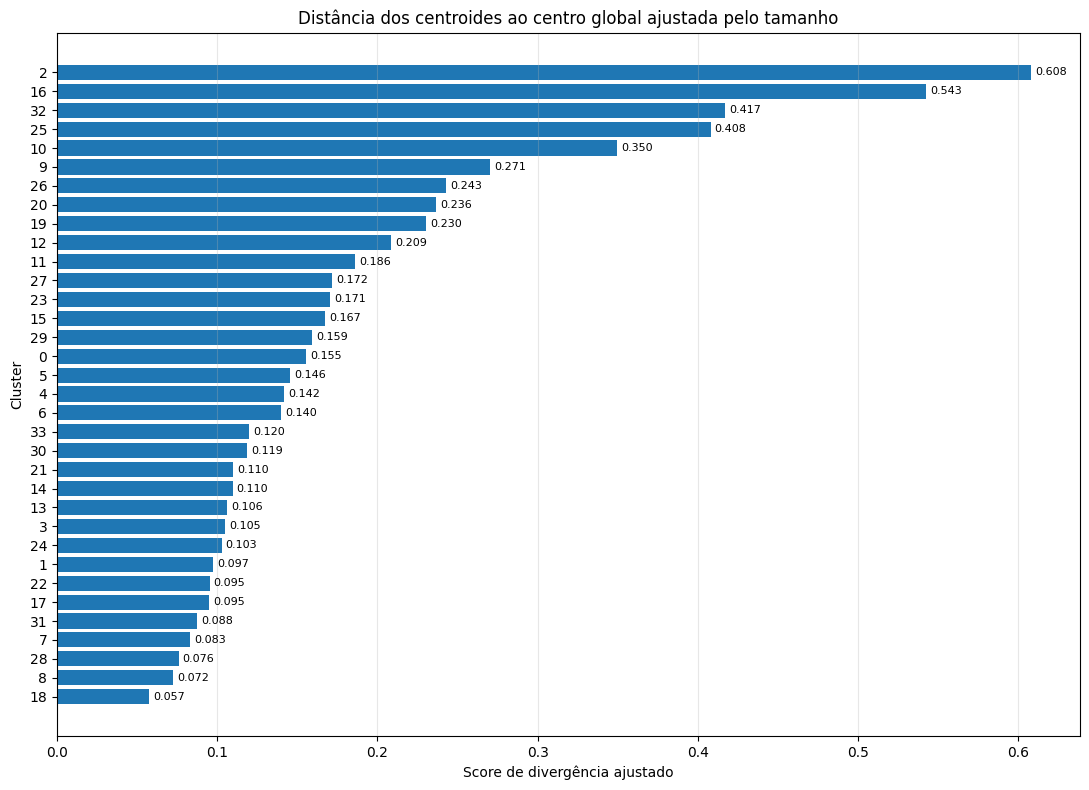


DISTÂNCIAS DOS REGISTROS AOS CENTROIDES


,cluster,registros,distancia_media,distancia_mediana,distancia_maxima
0,25,166,0.6738,0.6560,1.4500
1,16,178,0.5843,0.5486,1.4089
2,26,207,0.5717,0.5420,1.1734
3,20,251,0.4701,0.4554,1.2241
4,10,310,0.4678,0.4485,1.1983
5,32,91,0.4612,0.4860,1.0327
6,27,223,0.4592,0.4318,1.5105
7,2,78,0.4408,0.3712,1.1012
8,3,252,0.4351,0.4284,1.2787
9,30,262,0.4141,0.4072,0.9186


In [14]:
if X_scaled.shape[0] != len(df_ml_prep):
    raise ValueError(
        "X_scaled e df_ml_prep possuem quantidades diferentes de registros."
    )

if 'cluster_kmeans' not in df_ml_prep.columns:
    raise ValueError("A coluna cluster_kmeans não foi encontrada.")

rotulos = df_ml_prep['cluster_kmeans'].to_numpy()

if len(np.unique(rotulos)) != modelo_kmeans.n_clusters:
    raise ValueError("A quantidade de clusters encontrados é diferente da esperada.")

# ------------------------------------------------------------
# 2. Distância de cada registro ao centroide do próprio cluster
# ------------------------------------------------------------

distancias = modelo_kmeans.transform(X_scaled)

df_ml_prep['distancia_centroide_kmeans'] = distancias[
    np.arange(len(df_ml_prep)), rotulos
]

# ------------------------------------------------------------
# 3. Distância dos centroides ao centro global
# ------------------------------------------------------------

centro_global = X_scaled.mean(axis=0)
centros_clusters = modelo_kmeans.cluster_centers_

distancias_globais = np.linalg.norm(
    centros_clusters - centro_global,
    axis=1
)

# ------------------------------------------------------------
# 4. Quantidade de registros por cluster
# ------------------------------------------------------------

n_clusters = modelo_kmeans.n_clusters

tamanhos = (
    df_ml_prep['cluster_kmeans']
    .value_counts()
    .reindex(range(n_clusters), fill_value=0)
    .to_numpy()
)

# ------------------------------------------------------------
# 5. Score de divergência ajustado pelo tamanho
# ------------------------------------------------------------

score_divergencia = (
    distancias_globais / np.log2(tamanhos + 2)
)

resumo_clusters = pd.DataFrame({
    'cluster': np.arange(n_clusters),
    'quantidade': tamanhos,
    'distancia_centro_global': distancias_globais,
    'score_divergencia_ajustado': score_divergencia
})

# Acrescenta percentual de registros
resumo_clusters['percentual'] = (
    resumo_clusters['quantidade'] / len(df_ml_prep) * 100
)

# ------------------------------------------------------------
# 6. Ranking dos clusters mais divergentes
# ------------------------------------------------------------

print("CLUSTERS COM MAIOR DIVERGÊNCIA AJUSTADA")
print("-" * 60)

display(
    resumo_clusters
    .sort_values('score_divergencia_ajustado', ascending=False)
    .round(4)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. Gráfico horizontal
# ------------------------------------------------------------

grafico = resumo_clusters.sort_values(
    'score_divergencia_ajustado',
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

barras = ax.barh(
    grafico['cluster'].astype(str),
    grafico['score_divergencia_ajustado']
)

ax.bar_label(barras, fmt='%.3f', padding=3, fontsize=8)

ax.set_title(
    'Distância dos centroides ao centro global ajustada pelo tamanho'
)
ax.set_xlabel('Score de divergência ajustado')
ax.set_ylabel('Cluster')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Distância interna dos registros por cluster
# ------------------------------------------------------------

resumo_distancias_internas = (
    df_ml_prep
    .groupby('cluster_kmeans')
    .agg(
        registros=('distancia_centroide_kmeans', 'size'),
        distancia_media=('distancia_centroide_kmeans', 'mean'),
        distancia_mediana=('distancia_centroide_kmeans', 'median'),
        distancia_maxima=('distancia_centroide_kmeans', 'max')
    )
    .reset_index()
    .rename(columns={'cluster_kmeans': 'cluster'})
)

print("\nDISTÂNCIAS DOS REGISTROS AOS CENTROIDES")
display(
    resumo_distancias_internas
    .sort_values('distancia_media', ascending=False)
    .round(4)
    .reset_index(drop=True)
)


DELTAS DAS DISTÂNCIAS AO CENTRO GLOBAL
------------------------------------------------------------


,posicao,cluster,quantidade,distancia_centro_global,delta_distancia
0,1,16,178,4.0656,NaN
1,2,2,78,3.8449,0.2207
2,3,25,166,3.0157,0.8292
3,4,10,310,2.8988,0.1169
4,5,32,91,2.7273,0.1715
5,6,9,277,2.1979,0.5294
6,7,12,888,2.0446,0.1534
7,8,19,383,1.9761,0.0684
8,9,20,251,1.8871,0.0890
9,10,26,207,1.8695,0.0176



MAIORES SALTOS ENTRE CLUSTERS CONSECUTIVOS
------------------------------------------------------------
1º salto: Δ = 0.8292 | C2 → C25
2º salto: Δ = 0.5294 | C32 → C9

CLUSTERS CANDIDATOS PELO SEGUNDO MAIOR SALTO
------------------------------------------------------------


,cluster,quantidade,percentual,distancia_centro_global,score_divergencia_ajustado
0,16,178,0.9047,4.0656,0.5427
1,2,78,0.3964,3.8449,0.6082
2,25,166,0.8437,3.0157,0.4080
3,10,310,1.5755,2.8988,0.3499
4,32,91,0.4625,2.7273,0.4171


Quantidade de clusters candidatos: 5
Total de registros nesses clusters: 823


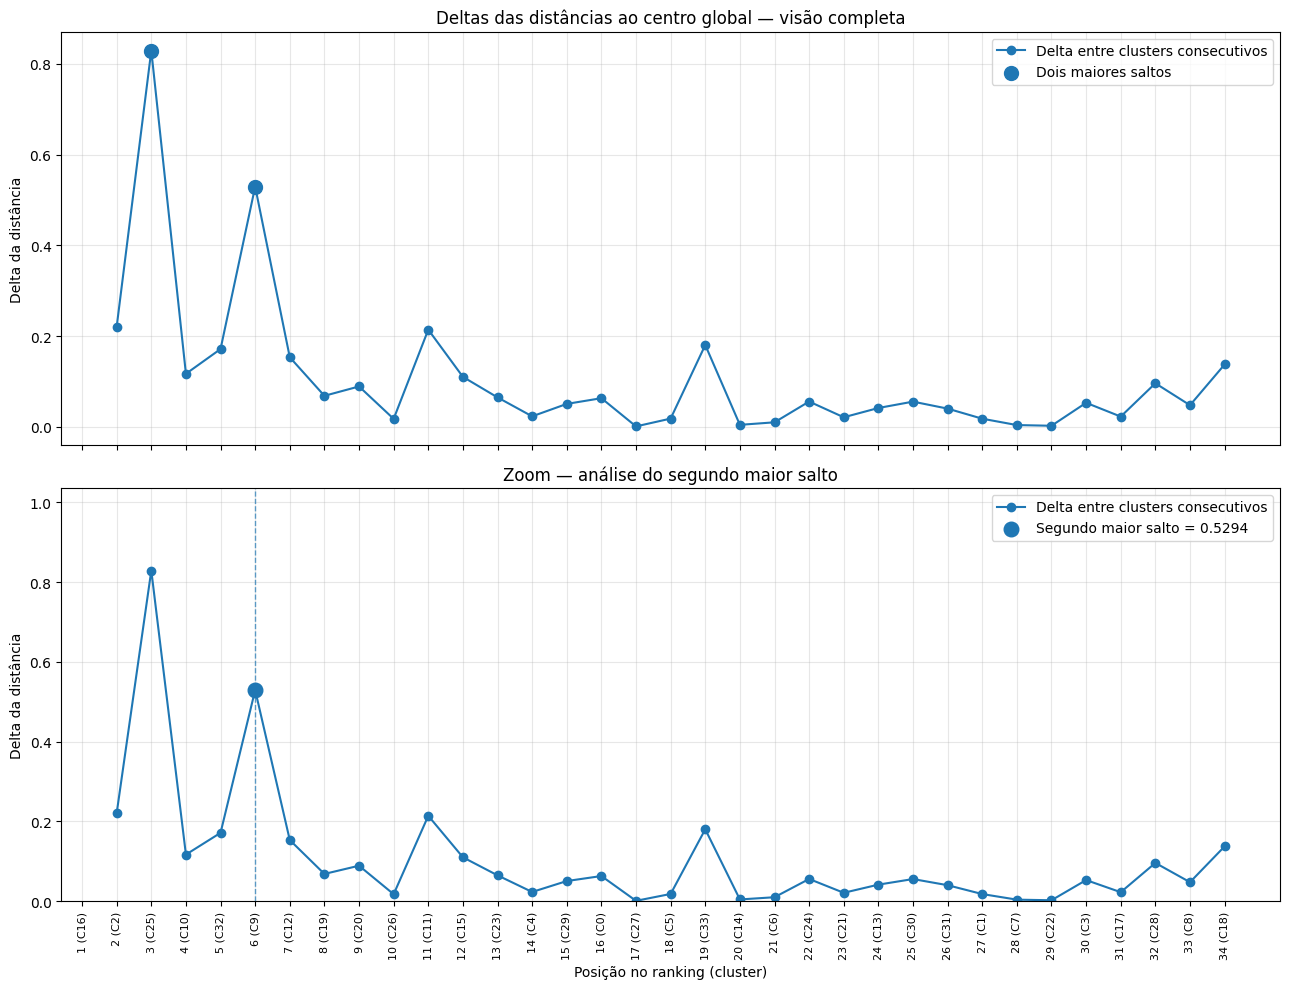

In [15]:
# ------------------------------------------------------------
# 1. Ordenação pela distância pura ao centro global
# ------------------------------------------------------------

df_ordenado = (
    resumo_clusters
    .sort_values('distancia_centro_global', ascending=False)
    .reset_index(drop=True)
    .copy()
)

df_ordenado['posicao'] = df_ordenado.index + 1

# Delta = distância do cluster anterior menos distância atual
df_ordenado['delta_distancia'] = (
    df_ordenado['distancia_centro_global'].shift(1)
    - df_ordenado['distancia_centro_global']
)

df_ordenado['rotulo'] = (
    df_ordenado['posicao'].astype(str)
    + ' (C' + df_ordenado['cluster'].astype(str) + ')'
)

# ------------------------------------------------------------
# 2. Exibição dos deltas
# ------------------------------------------------------------

print("DELTAS DAS DISTÂNCIAS AO CENTRO GLOBAL")
print("-" * 60)

display(
    df_ordenado[[
        'posicao',
        'cluster',
        'quantidade',
        'distancia_centro_global',
        'delta_distancia'
    ]].round(4).head(15)
)

# ------------------------------------------------------------
# 3. Identificação dos dois maiores saltos
# ------------------------------------------------------------

deltas_validos = df_ordenado['delta_distancia'].dropna()

if len(deltas_validos) < 2:
    raise ValueError("Não há deltas suficientes para identificar dois saltos.")

maiores_saltos = deltas_validos.nlargest(2)

idx_1 = maiores_saltos.index[0]
idx_2 = maiores_saltos.index[1]

maior_1 = df_ordenado.loc[idx_1, 'delta_distancia']
maior_2 = df_ordenado.loc[idx_2, 'delta_distancia']

print("\nMAIORES SALTOS ENTRE CLUSTERS CONSECUTIVOS")
print("-" * 60)

for numero, idx in enumerate([idx_1, idx_2], start=1):

    cluster_anterior = int(df_ordenado.loc[idx - 1, 'cluster'])
    cluster_atual = int(df_ordenado.loc[idx, 'cluster'])
    delta = df_ordenado.loc[idx, 'delta_distancia']

    print(
        f"{numero}º salto: Δ = {delta:.4f} | "
        f"C{cluster_anterior} → C{cluster_atual}"
    )

# ------------------------------------------------------------
# 4. Candidatos acima do segundo maior salto
# ------------------------------------------------------------

# Os clusters posicionados antes do segundo maior salto
# formam o conjunto candidato para investigação.

posicao_corte = int(df_ordenado.loc[idx_2, 'posicao'])

clusters_candidatos = (
    df_ordenado
    .iloc[:posicao_corte - 1]
    .copy()
)

print("\nCLUSTERS CANDIDATOS PELO SEGUNDO MAIOR SALTO")
print("-" * 60)

display(
    clusters_candidatos[[
        'cluster',
        'quantidade',
        'percentual',
        'distancia_centro_global',
        'score_divergencia_ajustado'
    ]].round(4)
)

print(
    f"Quantidade de clusters candidatos: "
    f"{len(clusters_candidatos)}"
)

print(
    f"Total de registros nesses clusters: "
    f"{clusters_candidatos['quantidade'].sum()}"
)

# ------------------------------------------------------------
# 5. Gráficos dos deltas
# ------------------------------------------------------------

x = df_ordenado['posicao'].iloc[1:]
y = df_ordenado['delta_distancia'].iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

# Painel superior: visão completa
ax = axes[0]

ax.plot(
    x, y,
    marker='o',
    linewidth=1.5,
    label='Delta entre clusters consecutivos'
)

ax.scatter(
    df_ordenado.loc[[idx_1, idx_2], 'posicao'],
    df_ordenado.loc[[idx_1, idx_2], 'delta_distancia'],
    s=100,
    zorder=5,
    label='Dois maiores saltos'
)

ax.set_ylabel('Delta da distância')
ax.set_title('Deltas das distâncias ao centro global — visão completa')
ax.legend()
ax.grid(alpha=0.3)

# Painel inferior: zoom sem o maior salto
ax = axes[1]

ax.plot(
    x, y,
    marker='o',
    linewidth=1.5,
    label='Delta entre clusters consecutivos'
)

ax.scatter(
    [df_ordenado.loc[idx_2, 'posicao']],
    [maior_2],
    s=110,
    zorder=5,
    label=f'Segundo maior salto = {maior_2:.4f}'
)

ax.axvline(
    df_ordenado.loc[idx_2, 'posicao'],
    linestyle='--',
    linewidth=1,
    alpha=0.7
)

# Limita o eixo para facilitar a visualização
ax.set_ylim(
    0,
    max(maiores_saltos.min() * 1.5, y.max() * 1.25)
)

ax.set_xlabel('Posição no ranking (cluster)')
ax.set_ylabel('Delta da distância')
ax.set_title('Zoom — análise do segundo maior salto')
ax.legend()
ax.grid(alpha=0.3)

ax.set_xticks(df_ordenado['posicao'])
ax.set_xticklabels(
    df_ordenado['rotulo'],
    rotation=90,
    fontsize=8
)

plt.tight_layout()
plt.show()


### Gerar as anomalias para os clusters 16, 2, 25, 10, 32

In [18]:
# Clusters identificados como divergentes
clusters_anomalos = [16, 2, 25, 10, 32]

# Confere a existência da coluna de clusters
if 'cluster_kmeans' not in df_ml_prep.columns:
    raise ValueError("A coluna cluster_kmeans não foi encontrada.")

# Marca todos os itens pertencentes aos clusters selecionados
df_ml_prep['anomalia_kmeans'] = (
    df_ml_prep['cluster_kmeans']
    .isin(clusters_anomalos)
).astype(int)

# Cria base contendo somente os itens anômalos
df_anomalias_kmeans = (
    df_ml_prep[
        df_ml_prep['anomalia_kmeans'] == 1
    ]
    .copy()
    .sort_values(
        ['cluster_kmeans', 'distancia_centroide_kmeans'],
        ascending=[True, False]
    )
)

# Resumo por cluster
resumo_anomalias_kmeans = (
    df_ml_prep
    .groupby('cluster_kmeans')
    .agg(
        total_itens=('cluster_kmeans', 'size'),
        itens_anomalos=('anomalia_kmeans', 'sum')
    )
    .reset_index()
)

resumo_anomalias_kmeans['percentual_anomalias'] = (
    resumo_anomalias_kmeans['itens_anomalos']
    / resumo_anomalias_kmeans['total_itens'] * 100
)

# Exibe somente os clusters selecionados
print("RESUMO DOS CLUSTERS CLASSIFICADOS COMO ANÔMALOS")

display(
    resumo_anomalias_kmeans[
        resumo_anomalias_kmeans['cluster_kmeans'].isin(clusters_anomalos)
    ].round(2)
)

# Resultado geral
total_anomalos = len(df_anomalias_kmeans)

print("\nRESULTADO GERAL")
print(f"Clusters selecionados: {clusters_anomalos}")
print(f"Total de registros na base: {len(df_ml_prep)}")
print(f"Total de itens anômalos: {total_anomalos}")
print(
    f"Percentual da base: "
    f"{total_anomalos / len(df_ml_prep) * 100:.2f}%"
)

# Conferência
print("\nCONFERÊNCIA")
print(
    "Todos os registros dos clusters selecionados foram classificados?",
    df_anomalias_kmeans['cluster_kmeans'].isin(clusters_anomalos).all()
)


RESUMO DOS CLUSTERS CLASSIFICADOS COMO ANÔMALOS


,cluster_kmeans,total_itens,itens_anomalos,percentual_anomalias
2,2,78,78,100.0
10,10,310,310,100.0
16,16,178,178,100.0
25,25,166,166,100.0
32,32,91,91,100.0



RESULTADO GERAL
Clusters selecionados: [16, 2, 25, 10, 32]
Total de registros na base: 19676
Total de itens anômalos: 823
Percentual da base: 4.18%

CONFERÊNCIA
Todos os registros dos clusters selecionados foram classificados? True


## Comparação dos métodos

In [19]:
# ------------------------------------------------------------
# 1. Conferência das marcações
# ------------------------------------------------------------

colunas_necessarias = [
    'anomalia_kmeans',
    'anomalia_isolation_forest'
]

for coluna in colunas_necessarias:
    if coluna not in df_ml_prep.columns:
        raise ValueError(f"Coluna {coluna} não encontrada.")

# ------------------------------------------------------------
# 2. Classificação conjunta
# ------------------------------------------------------------

df_comparacao = df_ml_prep.copy()

df_comparacao['anomalia_ambos'] = (
    (df_comparacao['anomalia_kmeans'] == 1) &
    (df_comparacao['anomalia_isolation_forest'] == 1)
).astype(int)

df_comparacao['somente_kmeans'] = (
    (df_comparacao['anomalia_kmeans'] == 1) &
    (df_comparacao['anomalia_isolation_forest'] == 0)
).astype(int)

df_comparacao['somente_iforest'] = (
    (df_comparacao['anomalia_kmeans'] == 0) &
    (df_comparacao['anomalia_isolation_forest'] == 1)
).astype(int)

df_comparacao['normal_ambos'] = (
    (df_comparacao['anomalia_kmeans'] == 0) &
    (df_comparacao['anomalia_isolation_forest'] == 0)
).astype(int)

# ------------------------------------------------------------
# 3. Resumo da comparação
# ------------------------------------------------------------

total = len(df_comparacao)

resumo_metodos = pd.DataFrame({
    'classificacao': [
        'Anomalias K-Means',
        'Anomalias Isolation Forest',
        'Anomalias em ambos',
        'Somente K-Means',
        'Somente Isolation Forest',
        'Normais em ambos'
    ],
    'quantidade': [
        df_comparacao['anomalia_kmeans'].sum(),
        df_comparacao['anomalia_isolation_forest'].sum(),
        df_comparacao['anomalia_ambos'].sum(),
        df_comparacao['somente_kmeans'].sum(),
        df_comparacao['somente_iforest'].sum(),
        df_comparacao['normal_ambos'].sum()
    ]
})

resumo_metodos['percentual_base'] = (
    resumo_metodos['quantidade'] / total * 100
)

print("COMPARAÇÃO ENTRE OS MÉTODOS")
display(resumo_metodos.round(2))

# ------------------------------------------------------------
# 4. Indicadores de concordância
# ------------------------------------------------------------

ambos = int(df_comparacao['anomalia_ambos'].sum())
total_kmeans = int(df_comparacao['anomalia_kmeans'].sum())
total_iforest = int(df_comparacao['anomalia_isolation_forest'].sum())

print("\nINDICADORES DE CONCORDÂNCIA")
print("-" * 50)

print(
    f"Interseção / K-Means: "
    f"{ambos / total_kmeans * 100 if total_kmeans else 0:.2f}%"
)

print(
    f"Interseção / Isolation Forest: "
    f"{ambos / total_iforest * 100 if total_iforest else 0:.2f}%"
)

print(
    f"Interseção / união dos métodos: "
    f"{ambos / (
        total_kmeans + total_iforest - ambos
    ) * 100 if (total_kmeans + total_iforest - ambos) else 0:.2f}%"
)

# ------------------------------------------------------------
# 5. Itens identificados pelos dois métodos
# ------------------------------------------------------------

df_anomalias_ambos = (
    df_comparacao[
        df_comparacao['anomalia_ambos'] == 1
    ]
    .sort_values(
        'score_isolation_forest',
        ascending=False
    )
    .copy()
)

colunas_exibicao = [
    'numero_processo',
    'ano_processo',
    'cluster_kmeans',
    'unidade',
    'fornecedor',
    'afastamento',
    'item',
    'valor_unitario',
    'quantidade',
    'valor_total_processo',
    'distancia_centroide_kmeans',
    'score_isolation_forest'
]

print("\nITENS IDENTIFICADOS PELOS DOIS MÉTODOS")
print(f"Total: {len(df_anomalias_ambos)}")

display(
    df_anomalias_ambos[colunas_exibicao]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. Itens exclusivos de cada método
# ------------------------------------------------------------

df_somente_kmeans = df_comparacao[
    df_comparacao['somente_kmeans'] == 1
].copy()

df_somente_iforest = df_comparacao[
    df_comparacao['somente_iforest'] == 1
].copy()

print("\nITENS IDENTIFICADOS SOMENTE PELO K-MEANS")
print(f"Total: {len(df_somente_kmeans)}")

print("\nITENS IDENTIFICADOS SOMENTE PELO ISOLATION FOREST")
print(f"Total: {len(df_somente_iforest)}")

# ------------------------------------------------------------
# 7. Cruzamento por cluster
# ------------------------------------------------------------

resumo_por_cluster = (
    df_comparacao
    .groupby('cluster_kmeans')
    .agg(
        total_itens=('cluster_kmeans', 'size'),
        anomalias_kmeans=('anomalia_kmeans', 'sum'),
        anomalias_iforest=('anomalia_isolation_forest', 'sum'),
        anomalias_ambos=('anomalia_ambos', 'sum')
    )
    .reset_index()
)

print("\nCOMPARAÇÃO POR CLUSTER")
display(
    resumo_por_cluster[
        resumo_por_cluster['cluster_kmeans'].isin(
            [16, 2, 25, 10, 32]
        )
    ].round(2)
)

# ------------------------------------------------------------
# 8. Conferência final
# ------------------------------------------------------------

print("\nCONFERÊNCIA")
print(
    "Total de registros:",
    len(df_comparacao)
)

print(
    "Soma das quatro classificações:",
    int(
        df_comparacao['anomalia_ambos'].sum()
        + df_comparacao['somente_kmeans'].sum()
        + df_comparacao['somente_iforest'].sum()
        + df_comparacao['normal_ambos'].sum()
    )
)


COMPARAÇÃO ENTRE OS MÉTODOS


,classificacao,quantidade,percentual_base
0,Anomalias K-Means,823,4.18
1,Anomalias Isolation Forest,984,5.00
2,Anomalias em ambos,561,2.85
3,Somente K-Means,262,1.33
4,Somente Isolation Forest,423,2.15
5,Normais em ambos,18430,93.67



INDICADORES DE CONCORDÂNCIA
--------------------------------------------------
Interseção / K-Means: 68.17%
Interseção / Isolation Forest: 57.01%
Interseção / união dos métodos: 45.02%

ITENS IDENTIFICADOS PELOS DOIS MÉTODOS
Total: 561


,numero_processo,ano_processo,cluster_kmeans,unidade,fornecedor,afastamento,item,valor_unitario,quantidade,valor_total_processo,distancia_centroide_kmeans,score_isolation_forest
0,SEI-260007/051021/2023,2023,16,UERJ - ADMINISTRACAO CENTRAL,CONQUISTA SERVICO E TERCEIRIZACAO DE MAO DE OB...,Dispensa - Especial,LIMPEZA PREDIAL - SERVICO: EMPRESA ESPECIALIZA...,2.14,4575529.80,9795294.20,1.223958,0.709607
1,SEI-080002/000349/2024,2024,16,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,LUVA PROCEDIMENTO DESCARTAVEL - TIPO: NAO ESTE...,0.28,12445505.00,4830946.10,1.408943,0.706062
2,SEI-260006/024108/2024,2024,16,UERJ - ADMINISTRACAO CENTRAL,CONQUISTA SERVICO E TERCEIRIZACAO DE MAO DE OB...,Dispensa de Licitação,SERVICOS DE LIMPEZA E CONSERVACAO DE AMBIENTE ...,2.58,2287764.87,5908839.11,1.006133,0.704336
3,SEI-080002/002636/2024,2024,16,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,"FRALDA GERIATRICA DESCARTAVEL - MODELO: CALCA,...",1.19,5433898.00,11919213.70,1.108484,0.700742
4,SEI-080002/003250/2024,2024,16,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,"S.M GUIMARÃES DISTRIBUIDORA, IMPORTDORA E EXPO...",Dispensa de Licitação,CONECTOR CATETER - MATERIAL: CLORETO POLIVILIN...,1.89,1611979.00,4271688.38,0.715180,0.698575
...,...,...,...,...,...,...,...,...,...,...,...,...
556,SEI-080007/001333/2023,2023,10,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PROMERJ COMÉRCIO DE PRODUTOS FARMACÊUTICOS EIRELI,Dispensa - Especial,"ALCOOL - TIPO: ALCOOL ETILICO, ASPECTO: LIQUI...",10.85,31260.00,8985700.40,0.513998,0.590327
557,SEI-040177/000636/2022,2023,25,SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,R. J. BRAGA SERVIÇOS E COMÉRCIO LTDA,Dispensa - Pequenas Compras,"ACUCAR - TIPO: ACUCAR REFINADO, FORNECIMENTO: ...",0.04,30500.00,15198.50,0.900611,0.590267
558,SEI-260004/000444/2023,2023,10,CECIERJ - FUND CENTRO CIÊN EDUC SUP DISTÂN DO ...,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,Dispensa - Especial,SERVICO DE CONFECCAO DE LIVROS - DESCRICAO: FO...,7.38,22500.00,6683825.00,0.386464,0.590260
559,SEI-080002/004267/2024,2024,10,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,NUTRIR SOLUÇÕES EM SAUDE EIRELI,Dispensa de Licitação,DIETA NUTRICIONAL COMPLETA - DESCRICAO: FORMUL...,39.95,21226.00,10533971.75,0.450407,0.589961



ITENS IDENTIFICADOS SOMENTE PELO K-MEANS
Total: 262

ITENS IDENTIFICADOS SOMENTE PELO ISOLATION FOREST
Total: 423

COMPARAÇÃO POR CLUSTER


,cluster_kmeans,total_itens,anomalias_kmeans,anomalias_iforest,anomalias_ambos
2,2,78,78,78,78
10,10,310,310,93,93
16,16,178,178,178,178
25,25,166,166,122,122
32,32,91,91,90,90



CONFERÊNCIA
Total de registros: 19676
Soma das quatro classificações: 19676


### Análise dos resultasdos

VISÃO GERAL DAS CLASSIFICAÇÕES
------------------------------------------------------------


,classificacao,itens,processos,fornecedores,unidades,valor_item_estimado,valor_unitario_mediano,percentual_itens
0,Ambos os métodos,561,222,127,29,1.570553e+09,13.00,2.85
1,Normal em ambos,18430,11065,3645,97,8.269454e+09,3032.54,93.67
2,Somente Isolation Forest,423,376,251,66,6.751435e+09,1490.00,2.15
3,Somente K-Means,262,89,55,15,4.075287e+07,9.47,1.33


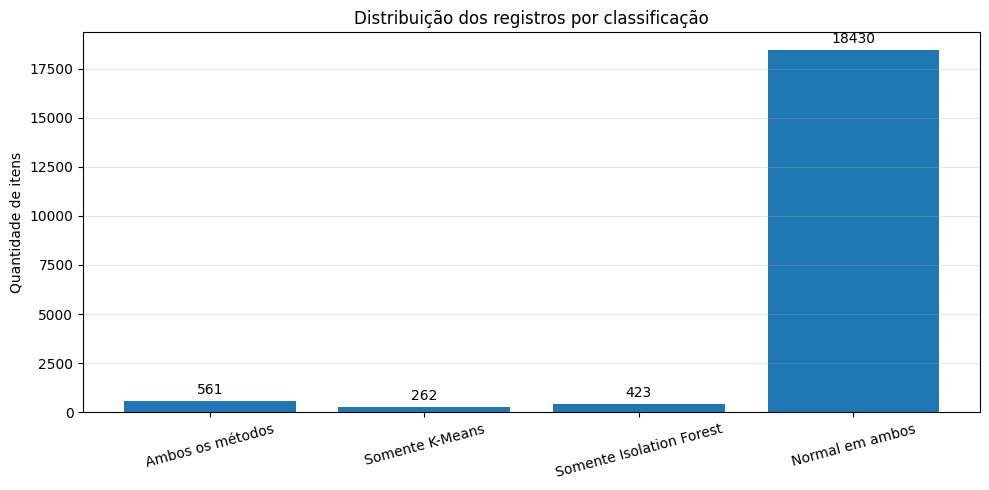


ANÁLISE DOS CLUSTERS SELECIONADOS
------------------------------------------------------------


,cluster_kmeans,itens,processos,fornecedores,unidades,valor_item_estimado,valor_unitario_medio,valor_unitario_mediano,anomalias_iforest,percentual_iforest
0,2,78,10,9,3,8.850234e+08,223.86,85.25,78,100.00
1,10,310,95,63,17,2.305740e+08,68.15,17.97,93,30.00
2,16,178,76,43,11,4.568421e+08,13.95,2.54,178,100.00
3,25,166,116,75,26,2.410598e+07,7.25,2.29,122,73.49
4,32,91,4,4,4,1.476026e+07,239.78,154.37,90,98.90



UNIDADES COM MAIS ITENS ANÔMALOS
------------------------------------------------------------


,unidade,itens,processos,fornecedores,valor_item_estimado,valor_unitario_mediano
9,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,313,87,62,1.787931e+08,4.43
20,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,194,29,15,1.105251e+09,154.10
15,SEAP - SECRETARIA DE ESTADO DE ADMIN.PENITENCI...,60,20,5,6.460256e+07,2.39
19,SEDSODH - SEC ESTADO DESEN SOCIAL E DE DIR HUM,42,10,6,1.652621e+07,3.64
4,FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA ...,38,4,3,3.515472e+07,44.47
6,FES - FUNDO ESTADUAL DE SAÚDE,34,20,18,4.537718e+07,23.38
30,UERJ - HOSPITAL UNIVERSITÁRIO - HOSPITAL UNIVE...,30,18,15,5.430934e+06,3.40
1,CECIERJ - FUND CENTRO CIÊN EDUC SUP DISTÂN DO ...,20,3,3,2.813246e+07,22.40
23,SEPM - Secretaria de Estado de Polícia Militar,16,6,5,1.729845e+07,8.31
29,UERJ - ADMINISTRACAO CENTRAL,15,9,5,2.491598e+07,2.58



FORNECEDORES COM MAIS ITENS ANÔMALOS
------------------------------------------------------------


,fornecedor,itens,processos,unidades,valor_item_estimado,valor_unitario_mediano
48,EUREKA SOLUCOES PEDAGOGICAS LTDA,112,4,1,5.569471e+08,197.25
89,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,93,36,2,7.967788e+07,2.94
42,EDITORA GLOBO S/A,54,3,2,2.189492e+07,40.00
65,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,41,6,5,2.076585e+07,17.95
79,"LOCASEM SERVIÇOS DE LIMPEZA, MANUTENÇÃO E ALIM...",32,5,1,2.569382e+06,4.09
98,NOVA LINEA COMERCIO DE PRODUTOS FARMACEUTICOS ...,31,18,2,6.094277e+06,1.70
127,SILITEC PRODUTOS HOSPITALARES LTDA,22,10,2,3.684319e+06,3.28
114,QUALYBEM FOOD E SERVICE S.A,18,3,1,3.382770e+07,2.58
139,VERONA SERVICOS LTDA,18,3,1,2.212262e+07,2.28
134,"TOTAL SUPRI COMERCIO, IMPORTACAO E EXPORTACAO ...",14,10,1,7.575196e+06,7.94


... (3 outputs left out)

,afastamento,itens,processos,fornecedores,valor_item_estimado
2,Dispensa de Licitação,344,123,85,3.745712e+08
0,Dispensa - Especial,206,69,38,1.881421e+08
5,Inexigibilidade - 14.133/2021,192,33,22,8.325236e+08
6,Inexigibilidade - Lei 8.666,60,8,10,2.154277e+08
1,Dispensa - Pequenas Compras,10,9,8,1.856480e+05
4,Inexigibilidade - 13.303/2016,9,1,1,3.807200e+05
3,Dispensa de Licitação 13.303/2016,2,2,1,7.476800e+04



PROCESSOS COM MAIS ITENS ANÔMALOS
------------------------------------------------------------


,id_processo,numero_processo,ano_processo,unidade,fornecedor,itens_anomalos,clusters,valor_itens_estimado,valor_total_processo,itens_iforest
25,1020,SEI-030001/069533/2024,2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,106,2,1.259488e+08,1.259498e+08,106
44,1361,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA GLOBO S/A,20,1,1.202636e+07,1.780971e+08,20
254,7811,SEI-260004/000444/2023,2023,CECIERJ - FUND CENTRO CIÊN EDUC SUP DISTÂN DO ...,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,18,1,6.534875e+06,6.683825e+06,3
299,9962,SEI-310003/000148/2023,2023,SEDSODH - SEC ESTADO DESEN SOCIAL E DE DIR HUM,"LOCASEM SERVIÇOS DE LIMPEZA, MANUTENÇÃO E ALIM...",18,1,1.196950e+06,1.196950e+06,0
257,7901,SEI-260005/000364/2025,2025,FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA ...,EDITORA GLOBO S/A,17,1,5.153785e+06,5.153785e+06,0
260,7991,SEI-260005/013535/2024,2024,FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA ...,EDITORA GLOBO S/A,17,1,4.714775e+06,4.714548e+06,0
46,1361,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,GESPED - GESTAO E ASSESSORIA EMPRESARIAL E EDU...,12,1,8.799035e+07,1.780971e+08,12
23,997,SEI-030001/042597/2024,2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,10,2,1.144697e+07,1.144697e+07,5
313,10673,SEI-350096/000172/2022,2023,SEPM - Secretaria de Estado de Polícia Militar,COMPANHIA BRASILEIRA DE CARTUCHOS (MATRIZ),9,2,8.058840e+06,8.058840e+06,5
159,2914,SEI-080002/004267/2024,2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,SUPPORT PRODUTOS NUTRICIONAIS LTDA,9,1,5.270957e+06,1.053397e+07,5



DISTRIBUIÇÃO DOS SCORES
------------------------------------------------------------


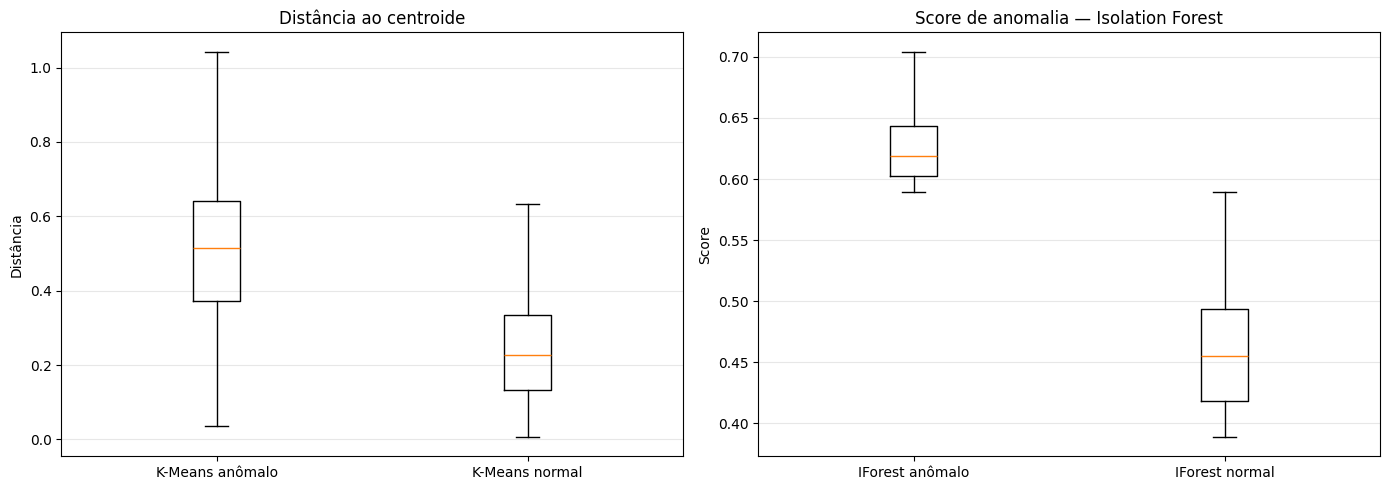


BASE DE PRIORIDADE PARA INVESTIGAÇÃO
------------------------------------------------------------
Itens identificados pelos dois métodos: 561


,numero_processo,ano_processo,cluster_kmeans,unidade,fornecedor,afastamento,item,valor_unitario,quantidade,valor_calculado_item,valor_total_processo,distancia_centroide_kmeans,score_isolation_forest
0,SEI-260007/051021/2023,2023,16,UERJ - ADMINISTRACAO CENTRAL,CONQUISTA SERVICO E TERCEIRIZACAO DE MAO DE OB...,Dispensa - Especial,LIMPEZA PREDIAL - SERVICO: EMPRESA ESPECIALIZA...,2.14,4575529.80,9791633.77,9795294.20,1.223958,0.709607
1,SEI-080002/000349/2024,2024,16,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,LUVA PROCEDIMENTO DESCARTAVEL - TIPO: NAO ESTE...,0.28,12445505.00,3484741.40,4830946.10,1.408943,0.706062
2,SEI-260006/024108/2024,2024,16,UERJ - ADMINISTRACAO CENTRAL,CONQUISTA SERVICO E TERCEIRIZACAO DE MAO DE OB...,Dispensa de Licitação,SERVICOS DE LIMPEZA E CONSERVACAO DE AMBIENTE ...,2.58,2287764.87,5902433.36,5908839.11,1.006133,0.704336
3,SEI-080002/002636/2024,2024,16,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,Dispensa de Licitação,"FRALDA GERIATRICA DESCARTAVEL - MODELO: CALCA,...",1.19,5433898.00,6466338.62,11919213.70,1.108484,0.700742
4,SEI-080002/003250/2024,2024,16,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,"S.M GUIMARÃES DISTRIBUIDORA, IMPORTDORA E EXPO...",Dispensa de Licitação,CONECTOR CATETER - MATERIAL: CLORETO POLIVILIN...,1.89,1611979.00,3046640.31,4271688.38,0.715180,0.698575
...,...,...,...,...,...,...,...,...,...,...,...,...,...
556,SEI-080007/001333/2023,2023,10,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PROMERJ COMÉRCIO DE PRODUTOS FARMACÊUTICOS EIRELI,Dispensa - Especial,"ALCOOL - TIPO: ALCOOL ETILICO, ASPECTO: LIQUI...",10.85,31260.00,339171.00,8985700.40,0.513998,0.590327
557,SEI-040177/000636/2022,2023,25,SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,R. J. BRAGA SERVIÇOS E COMÉRCIO LTDA,Dispensa - Pequenas Compras,"ACUCAR - TIPO: ACUCAR REFINADO, FORNECIMENTO: ...",0.04,30500.00,1220.00,15198.50,0.900611,0.590267
558,SEI-260004/000444/2023,2023,10,CECIERJ - FUND CENTRO CIÊN EDUC SUP DISTÂN DO ...,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,Dispensa - Especial,SERVICO DE CONFECCAO DE LIVROS - DESCRICAO: FO...,7.38,22500.00,166050.00,6683825.00,0.386464,0.590260
559,SEI-080002/004267/2024,2024,10,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,NUTRIR SOLUÇÕES EM SAUDE EIRELI,Dispensa de Licitação,DIETA NUTRICIONAL COMPLETA - DESCRICAO: FORMUL...,39.95,21226.00,847978.70,10533971.75,0.450407,0.589961


In [20]:
# ============================================================
# 1. PREPARAÇÃO DA BASE DE EXPLORAÇÃO
# ============================================================

df_exploracao = df_comparacao.copy()

# Classificação de cada registro
condicoes = [
    (df_exploracao['anomalia_kmeans'] == 1) &
    (df_exploracao['anomalia_isolation_forest'] == 1),

    (df_exploracao['anomalia_kmeans'] == 1) &
    (df_exploracao['anomalia_isolation_forest'] == 0),

    (df_exploracao['anomalia_kmeans'] == 0) &
    (df_exploracao['anomalia_isolation_forest'] == 1)
]

classificacoes = [
    'Ambos os métodos',
    'Somente K-Means',
    'Somente Isolation Forest'
]

df_exploracao['classificacao'] = np.select(
    condicoes,
    classificacoes,
    default='Normal em ambos'
)

# Conversão das variáveis financeiras
colunas_valores = [
    'valor_unitario',
    'valor_calculado_item',
    'valor_total_processo'
]

for coluna in colunas_valores:
    df_exploracao[coluna] = pd.to_numeric(
        df_exploracao[coluna],
        errors='coerce'
    )

# ============================================================
# 2. VISÃO GERAL DAS CLASSIFICAÇÕES
# ============================================================

print("VISÃO GERAL DAS CLASSIFICAÇÕES")
print("-" * 60)

resumo_geral = (
    df_exploracao
    .groupby('classificacao')
    .agg(
        itens=('id_item_compra', 'count'),
        processos=('id_processo', 'nunique'),
        fornecedores=('fornecedor', 'nunique'),
        unidades=('unidade', 'nunique'),
        valor_item_estimado=('valor_calculado_item', 'sum'),
        valor_unitario_mediano=('valor_unitario', 'median')
    )
    .reset_index()
)

resumo_geral['percentual_itens'] = (
    resumo_geral['itens'] / len(df_exploracao) * 100
)

display(resumo_geral.round(2))

# Gráfico da distribuição
ordem = [
    'Ambos os métodos',
    'Somente K-Means',
    'Somente Isolation Forest',
    'Normal em ambos'
]

contagem = (
    df_exploracao['classificacao']
    .value_counts()
    .reindex(ordem, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(contagem.index, contagem.values)
ax.bar_label(barras, padding=3)

ax.set_title('Distribuição dos registros por classificação')
ax.set_ylabel('Quantidade de itens')
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 3. ANÁLISE DOS CLUSTERS SELECIONADOS
# ============================================================

print("\nANÁLISE DOS CLUSTERS SELECIONADOS")
print("-" * 60)

resumo_clusters = (
    df_exploracao[
        df_exploracao['cluster_kmeans'].isin(clusters_anomalos)
    ]
    .groupby('cluster_kmeans')
    .agg(
        itens=('id_item_compra', 'count'),
        processos=('id_processo', 'nunique'),
        fornecedores=('fornecedor', 'nunique'),
        unidades=('unidade', 'nunique'),
        valor_item_estimado=('valor_calculado_item', 'sum'),
        valor_unitario_medio=('valor_unitario', 'mean'),
        valor_unitario_mediano=('valor_unitario', 'median'),
        anomalias_iforest=('anomalia_isolation_forest', 'sum')
    )
    .reset_index()
)

resumo_clusters['percentual_iforest'] = (
    resumo_clusters['anomalias_iforest']
    / resumo_clusters['itens'] * 100
)

display(resumo_clusters.round(2))

# ============================================================
# 4. ANÁLISE POR UNIDADE
# ============================================================

print("\nUNIDADES COM MAIS ITENS ANÔMALOS")
print("-" * 60)

df_unidades = (
    df_exploracao[
        df_exploracao['anomalia_kmeans'] == 1
    ]
    .groupby('unidade')
    .agg(
        itens=('id_item_compra', 'count'),
        processos=('id_processo', 'nunique'),
        fornecedores=('fornecedor', 'nunique'),
        valor_item_estimado=('valor_calculado_item', 'sum'),
        valor_unitario_mediano=('valor_unitario', 'median')
    )
    .reset_index()
    .sort_values('itens', ascending=False)
)

display(df_unidades.head(15).round(2))

# ============================================================
# 5. ANÁLISE POR FORNECEDOR
# ============================================================

print("\nFORNECEDORES COM MAIS ITENS ANÔMALOS")
print("-" * 60)

df_fornecedores = (
    df_exploracao[
        df_exploracao['anomalia_kmeans'] == 1
    ]
    .groupby('fornecedor')
    .agg(
        itens=('id_item_compra', 'count'),
        processos=('id_processo', 'nunique'),
        unidades=('unidade', 'nunique'),
        valor_item_estimado=('valor_calculado_item', 'sum'),
        valor_unitario_mediano=('valor_unitario', 'median')
    )
    .reset_index()
    .sort_values('itens', ascending=False)
)

display(df_fornecedores.head(15).round(2))

# ============================================================
# 6. ANÁLISE DOS ITENS MAIS FREQUENTES
# ============================================================

print("\nITENS MAIS FREQUENTES NAS ANOMALIAS")
print("-" * 60)

df_itens = (
    df_exploracao[
        df_exploracao['anomalia_kmeans'] == 1
    ]
    .groupby('item')
    .agg(
        ocorrencias=('id_item_compra', 'count'),
        processos=('id_processo', 'nunique'),
        fornecedores=('fornecedor', 'nunique'),
        unidades=('unidade', 'nunique'),
        valor_unitario_mediano=('valor_unitario', 'median')
    )
    .reset_index()
    .sort_values('ocorrencias', ascending=False)
)

display(df_itens.head(20).round(2))

# ============================================================
# 7. ANÁLISE DOS AFASTAMENTOS
# ============================================================

print("\nANOMALIAS POR TIPO DE AFASTAMENTO")
print("-" * 60)

df_afastamentos = (
    df_exploracao[
        df_exploracao['anomalia_kmeans'] == 1
    ]
    .groupby('afastamento', dropna=False)
    .agg(
        itens=('id_item_compra', 'count'),
        processos=('id_processo', 'nunique'),
        fornecedores=('fornecedor', 'nunique'),
        valor_item_estimado=('valor_calculado_item', 'sum')
    )
    .reset_index()
    .sort_values('itens', ascending=False)
)

display(df_afastamentos.head(20).round(2))

# ============================================================
# 8. PROCESSOS COM MAIOR CONCENTRAÇÃO DE ITENS ANÔMALOS
# ============================================================

print("\nPROCESSOS COM MAIS ITENS ANÔMALOS")
print("-" * 60)

df_processos = (
    df_exploracao[
        df_exploracao['anomalia_kmeans'] == 1
    ]
    .groupby(
        ['id_processo', 'numero_processo', 'ano_processo',
         'unidade', 'fornecedor'],
        dropna=False
    )
    .agg(
        itens_anomalos=('id_item_compra', 'count'),
        clusters=('cluster_kmeans', 'nunique'),
        valor_itens_estimado=('valor_calculado_item', 'sum'),
        valor_total_processo=('valor_total_processo', 'first'),
        itens_iforest=('anomalia_isolation_forest', 'sum')
    )
    .reset_index()
    .sort_values(
        ['itens_anomalos', 'valor_itens_estimado'],
        ascending=False
    )
)

display(df_processos.head(20).round(2))

# ============================================================
# 9. DISTRIBUIÇÃO DOS SCORES DOS MÉTODOS
# ============================================================

print("\nDISTRIBUIÇÃO DOS SCORES")
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distância ao centroide
axes[0].boxplot(
    [
        df_exploracao.loc[
            df_exploracao['anomalia_kmeans'] == 1,
            'distancia_centroide_kmeans'
        ].dropna(),
        df_exploracao.loc[
            df_exploracao['anomalia_kmeans'] == 0,
            'distancia_centroide_kmeans'
        ].dropna()
    ],
    tick_labels=['K-Means anômalo', 'K-Means normal'],
    showfliers=False
)

axes[0].set_title('Distância ao centroide')
axes[0].set_ylabel('Distância')
axes[0].grid(axis='y', alpha=0.3)

# Score do Isolation Forest
axes[1].boxplot(
    [
        df_exploracao.loc[
            df_exploracao['anomalia_isolation_forest'] == 1,
            'score_isolation_forest'
        ].dropna(),
        df_exploracao.loc[
            df_exploracao['anomalia_isolation_forest'] == 0,
            'score_isolation_forest'
        ].dropna()
    ],
    tick_labels=['IForest anômalo', 'IForest normal'],
    showfliers=False
)

axes[1].set_title('Score de anomalia — Isolation Forest')
axes[1].set_ylabel('Score')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 10. BASE FINAL PARA INVESTIGAÇÃO
# ============================================================

df_prioridade_investigacao = (
    df_exploracao[
        df_exploracao['anomalia_ambos'] == 1
    ]
    .sort_values(
        'score_isolation_forest',
        ascending=False
    )
    .copy()
)

print("\nBASE DE PRIORIDADE PARA INVESTIGAÇÃO")
print("-" * 60)
print(f"Itens identificados pelos dois métodos: "
      f"{len(df_prioridade_investigacao)}")

display(
    df_prioridade_investigacao[
        [
            'numero_processo',
            'ano_processo',
            'cluster_kmeans',
            'unidade',
            'fornecedor',
            'afastamento',
            'item',
            'valor_unitario',
            'quantidade',
            'valor_calculado_item',
            'valor_total_processo',
            'distancia_centroide_kmeans',
            'score_isolation_forest'
        ]
    ].reset_index(drop=True)
)


## Criar colunas para receber dados no SupaBase

In [21]:
# Colunas novas na tabela fato_item_compra
comandos_sql = [
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS cluster_kmeans INTEGER
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS anomalia_kmeans SMALLINT
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS score_isolation_forest NUMERIC
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS distancia_centroide_kmeans NUMERIC
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS flag_anomalia_ambos SMALLINT
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS flag_anomalia_somente_kmeans SMALLINT
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS flag_anomalia_somente_iforest SMALLINT
    """,
    """
    ALTER TABLE public.fato_item_compra
    ADD COLUMN IF NOT EXISTS flag_normal_ambos SMALLINT
    """
]

# Executar alterações em uma transação
with engine.begin() as conn:
    for comando in comandos_sql:
        conn.execute(text(comando))

print("Colunas verificadas/criadas com sucesso!")


# Conferir a estrutura atualizada da tabela
consulta_colunas = """
SELECT
    column_name,
    data_type,
    is_nullable
FROM information_schema.columns
WHERE table_schema = 'public'
  AND table_name = 'fato_item_compra'
ORDER BY ordinal_position
"""

with engine.connect() as conn:
    df_estrutura_atualizada = pd.read_sql(
        text(consulta_colunas), conn
    )

display(df_estrutura_atualizada)


Colunas verificadas/criadas com sucesso!


,column_name,data_type,is_nullable
0,id_item_compra,bigint,NO
1,id_processo,integer,NO
2,id_unidade,integer,NO
3,id_fornecedor,integer,NO
4,id_afastamento,integer,NO
5,descricao_item,text,NO
6,unidade_medida,character varying,NO
7,quantidade,numeric,NO
8,valor_unitario,numeric,NO
9,valor_calculado_item,numeric,YES


## Exportar resultados para o Supabase

In [23]:
# ============================================================
# 1. PREPARAR OS RESULTADOS
# ============================================================

mapeamento = {
    'id_item_compra': 'id_item_compra',
    'cluster_kmeans': 'cluster_kmeans',
    'anomalia_kmeans': 'anomalia_kmeans',
    'anomalia_isolation_forest': 'flag_anomalia_isolation_forest',
    'score_isolation_forest': 'score_isolation_forest',
    'distancia_centroide_kmeans': 'distancia_centroide_kmeans',
    'anomalia_ambos': 'flag_anomalia_ambos',
    'somente_kmeans': 'flag_anomalia_somente_kmeans',
    'somente_iforest': 'flag_anomalia_somente_iforest',
    'normal_ambos': 'flag_normal_ambos'
}

faltantes = [
    coluna for coluna in mapeamento
    if coluna not in df_comparacao.columns
]

if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

df_salvar = (
    df_comparacao[list(mapeamento.keys())]
    .rename(columns=mapeamento)
    .copy()
)

# Conferir identificadores
df_salvar['id_item_compra'] = pd.to_numeric(
    df_salvar['id_item_compra'], errors='raise'
)

if df_salvar['id_item_compra'].isna().any():
    raise ValueError("Existem IDs de itens nulos.")

if df_salvar['id_item_compra'].duplicated().any():
    raise ValueError("Existem IDs de itens duplicados.")

df_salvar['id_item_compra'] = (
    df_salvar['id_item_compra'].astype('int64')
)

# Converter cluster
df_salvar['cluster_kmeans'] = pd.to_numeric(
    df_salvar['cluster_kmeans'], errors='raise'
).astype('int64')

# Converter flags
colunas_flags = [
    'anomalia_kmeans',
    'flag_anomalia_isolation_forest',
    'flag_anomalia_ambos',
    'flag_anomalia_somente_kmeans',
    'flag_anomalia_somente_iforest',
    'flag_normal_ambos'
]

for col in colunas_flags:
    df_salvar[col] = (
        pd.to_numeric(df_salvar[col], errors='raise')
        .fillna(0)
        .astype('int16')
    )

# Converter scores e distâncias
for col in [
    'score_isolation_forest',
    'distancia_centroide_kmeans'
]:
    df_salvar[col] = pd.to_numeric(
        df_salvar[col], errors='coerce'
    )

df_salvar = df_salvar.replace([np.inf, -np.inf], np.nan)

# ============================================================
# 2. PREPARAR A ATUALIZAÇÃO EM LOTES
# ============================================================

colunas_atualizacao = [
    'cluster_kmeans',
    'anomalia_kmeans',
    'flag_anomalia_isolation_forest',
    'score_isolation_forest',
    'distancia_centroide_kmeans',
    'flag_anomalia_ambos',
    'flag_anomalia_somente_kmeans',
    'flag_anomalia_somente_iforest',
    'flag_normal_ambos'
]

colunas_sql = ['id_item_compra'] + colunas_atualizacao

def converter_valor(valor):
    if pd.isna(valor):
        return None
    if isinstance(valor, np.generic):
        return valor.item()
    return valor

# Tamanho do lote
TAMANHO_LOTE = 500

total_registros = len(df_salvar)
total_atualizados = 0

# ============================================================
# 3. EXECUTAR UPDATE EM BLOCOS
# ============================================================

with engine.begin() as conn:

    for inicio in range(0, total_registros, TAMANHO_LOTE):

        lote = df_salvar.iloc[
            inicio:inicio + TAMANHO_LOTE
        ]

        parametros = {}
        valores_sql = []

        for indice, linha in enumerate(
            lote.itertuples(index=False, name=None)
        ):

            placeholders = []

            for coluna, valor in zip(colunas_sql, linha):

                nome_parametro = f'{coluna}_{indice}'

                parametros[nome_parametro] = converter_valor(
                    valor
                )

                placeholders.append(f':{nome_parametro}')

            valores_sql.append(
                '(' + ', '.join(placeholders) + ')'
            )

        # Montar a atualização do lote
        valores = ', '.join(valores_sql)

        atribuicoes = ', '.join(
            f'{coluna} = dados.{coluna}'
            for coluna in colunas_atualizacao
        )

        sql = f"""
            UPDATE public.fato_item_compra AS f
            SET {atribuicoes}
            FROM (
                VALUES {valores}
            ) AS dados ({', '.join(colunas_sql)})
            WHERE f.id_item_compra = dados.id_item_compra
        """

        resultado = conn.execute(text(sql), parametros)

        total_atualizados += resultado.rowcount

        print(
            f"Lote processado: "
            f"{min(inicio + TAMANHO_LOTE, total_registros):,}"
            f" de {total_registros:,}"
        )

# ============================================================
# 4. CONFERIR A GRAVAÇÃO
# ============================================================

consulta = text("""
    SELECT
        COUNT(*) AS total_itens,
        COUNT(cluster_kmeans) AS itens_com_kmeans,
        COUNT(anomalia_kmeans) AS itens_com_flag_kmeans,
        COUNT(flag_anomalia_isolation_forest)
            AS itens_com_flag_iforest,
        COUNT(score_isolation_forest)
            AS itens_com_score_iforest,
        COUNT(distancia_centroide_kmeans)
            AS itens_com_distancia,
        SUM(anomalia_kmeans) AS total_anomalias_kmeans,
        SUM(flag_anomalia_isolation_forest)
            AS total_anomalias_iforest,
        SUM(flag_anomalia_ambos)
            AS total_anomalias_ambos
    FROM public.fato_item_compra
""")

with engine.connect() as conn:
    df_conferencia = pd.read_sql(consulta, conn)

print("\nGRAVAÇÃO FINALIZADA")
print(f"Registros enviados: {total_registros:,}")
print(f"Registros atualizados: {total_atualizados:,}")

display(df_conferencia)


Lote processado: 500 de 19,676
Lote processado: 1,000 de 19,676
Lote processado: 1,500 de 19,676
Lote processado: 2,000 de 19,676
Lote processado: 2,500 de 19,676
Lote processado: 3,000 de 19,676
Lote processado: 3,500 de 19,676
Lote processado: 4,000 de 19,676
Lote processado: 4,500 de 19,676
Lote processado: 5,000 de 19,676
Lote processado: 5,500 de 19,676
Lote processado: 6,000 de 19,676
Lote processado: 6,500 de 19,676
Lote processado: 7,000 de 19,676
Lote processado: 7,500 de 19,676
Lote processado: 8,000 de 19,676
Lote processado: 8,500 de 19,676
Lote processado: 9,000 de 19,676
Lote processado: 9,500 de 19,676
Lote processado: 10,000 de 19,676
Lote processado: 10,500 de 19,676
Lote processado: 11,000 de 19,676
Lote processado: 11,500 de 19,676
Lote processado: 12,000 de 19,676
Lote processado: 12,500 de 19,676
Lote processado: 13,000 de 19,676
Lote processado: 13,500 de 19,676
Lote processado: 14,000 de 19,676
Lote processado: 14,500 de 19,676
Lote processado: 15,000 de 19,676
L

,total_itens,itens_com_kmeans,itens_com_flag_kmeans,itens_com_flag_iforest,itens_com_score_iforest,itens_com_distancia,total_anomalias_kmeans,total_anomalias_iforest,total_anomalias_ambos
0,19676,19676,19676,19676,19676,19676,823,984,561


## Salvar em Parquet

In [24]:
# ============================================================
# 1. PREPARAR A BASE COMPLETA
# ============================================================

# df_comparacao contém os dados originais e resultados dos modelos
df_parquet = df_comparacao.copy()

# ============================================================
# 2. GARANTIR OS TIPOS NUMÉRICOS
# ============================================================

colunas_numericas = [
    'valor_total_processo',
    'quantidade',
    'valor_unitario',
    'valor_calculado_item',
    'log_valor_unitario',
    'log_valor_processo',
    'log_quantidade',
    'proporcao_item_processo',
    'score_isolation_forest',
    'distancia_centroide_kmeans'
]

for col in colunas_numericas:
    if col in df_parquet.columns:
        df_parquet[col] = pd.to_numeric(
            df_parquet[col],
            errors='coerce'
        )

# ============================================================
# 3. CONFERIR OS RESULTADOS DO ML
# ============================================================

colunas_ml = [
    'cluster_kmeans',
    'anomalia_kmeans',
    'anomalia_isolation_forest',
    'score_isolation_forest',
    'distancia_centroide_kmeans',
    'anomalia_ambos',
    'somente_kmeans',
    'somente_iforest',
    'normal_ambos'
]

print("Conferência das colunas de ML:")

for col in colunas_ml:
    if col in df_parquet.columns:
        print(f"{col}: presente")
    else:
        print(f"{col}: NÃO ENCONTRADA")

# ============================================================
# 4. SALVAR ARQUIVO PARQUET
# ============================================================

caminho_parquet = Path('/content/compras_diretas_ml_completo.parquet')

df_parquet.to_parquet(
    caminho_parquet,
    engine='pyarrow',
    index=False,
    compression='snappy'
)

# ============================================================
# 5. VALIDAR O ARQUIVO
# ============================================================

df_validacao = pd.read_parquet(caminho_parquet)

print("\nEXPORTAÇÃO CONCLUÍDA")
print(f"Arquivo: {caminho_parquet.name}")
print(f"Registros: {len(df_validacao):,}")
print(f"Colunas: {len(df_validacao.columns)}")
print(f"Tamanho: {caminho_parquet.stat().st_size / (1024**2):.2f} MB")

print("\nConferência dos resultados:")
display(
    df_validacao[
        [col for col in colunas_ml if col in df_validacao.columns]
    ].describe(include='all').T
)

# ============================================================
# 6. DOWNLOAD NO GOOGLE COLAB
# ============================================================

from google.colab import files

files.download(str(caminho_parquet))


Conferência das colunas de ML:
cluster_kmeans: presente
anomalia_kmeans: presente
anomalia_isolation_forest: presente
score_isolation_forest: presente
distancia_centroide_kmeans: presente
anomalia_ambos: presente
somente_kmeans: presente
somente_iforest: presente
normal_ambos: presente

EXPORTAÇÃO CONCLUÍDA
Arquivo: compras_diretas_ml_completo.parquet
Registros: 19,676
Colunas: 33
Tamanho: 3.20 MB

Conferência dos resultados:


,count,mean,std,min,25%,50%,75%,max
cluster_kmeans,19676.0,16.278563,9.591849,0.000000,7.000000,15.000000,24.000000,33.000000
anomalia_kmeans,19676.0,0.041828,0.200200,0.000000,0.000000,0.000000,0.000000,1.000000
anomalia_isolation_forest,19676.0,0.050010,0.217971,0.000000,0.000000,0.000000,0.000000,1.000000
score_isolation_forest,19676.0,0.468481,0.061352,0.388888,0.422717,0.457577,0.503036,0.709607
distancia_centroide_kmeans,19676.0,0.263441,0.175112,0.006575,0.139148,0.233578,0.345597,2.167096
anomalia_ambos,19676.0,0.028512,0.166434,0.000000,0.000000,0.000000,0.000000,1.000000
somente_kmeans,19676.0,0.013316,0.114626,0.000000,0.000000,0.000000,0.000000,1.000000
somente_iforest,19676.0,0.021498,0.145042,0.000000,0.000000,0.000000,0.000000,1.000000
normal_ambos,19676.0,0.936674,0.243554,0.000000,1.000000,1.000000,1.000000,1.000000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>